In [2]:
%pip install xarray netCDF4

     ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
      --------------------------------------- 0.0/1.3 MB 1.4 MB/s eta 0:00:01
     -- ------------------------------------- 0.1/1.3 MB 1.3 MB/s eta 0:00:01
     ------ --------------------------------- 0.2/1.3 MB 2.0 MB/s eta 0:00:01
     ------------ --------------------------- 0.4/1.3 MB 2.5 MB/s eta 0:00:01
     --------------------- ------------------ 0.7/1.3 MB 3.8 MB/s eta 0:00:01
     ------------------------------ --------- 1.0/1.3 MB 4.2 MB/s eta 0:00:01
     ------------------------------------- -- 1.2/1.3 MB 4.4 MB/s eta 0:00:01
     ---------------------------------------- 1.3/1.3 MB 4.0 MB/s eta 0:00:00
     ---------------------------------------- 0.0/21.4 MB ? eta -:--:--
     ---------------------------------------- 0.1/21.4 MB 3.3 MB/s eta 0:00:07
      --------------------------------------- 0.4/21.4 MB 4.6 MB/s eta 0:00:05
      --------------------------------------- 0.4/21.4 MB 3.3 MB/s eta 0:00

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

arabian_path = (
    PROJECT_ROOT / "data" / "processed" / "copernicus"
    / "arabian_sea" / "copernicus_2019_2025.nc"
)

bengal_path = (
    PROJECT_ROOT / "data" / "processed" / "copernicus"
    / "bay_of_bengal" / "copernicus_2019_2025.nc"
)

print("Project root:", PROJECT_ROOT)
print("Arabian Sea file exists:", arabian_path.exists())
print("Bay of Bengal file exists:", bengal_path.exists())

Project root: c:\Users\91911\oceanographic-ai-platform
Arabian Sea file exists: True
Bay of Bengal file exists: True


In [5]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

arabian_path = (
    PROJECT_ROOT / "data" / "processed" / "copernicus"
    / "arabian_sea" / "copernicus_2019_2025.nc"
)

bengal_path = (
    PROJECT_ROOT / "data" / "processed" / "copernicus"
    / "bay_of_bengal" / "copernicus_2019_2025.nc"
)

arabian = xr.open_dataset(arabian_path)
bengal = xr.open_dataset(bengal_path)

print("ARABIAN SEA DATASET")
print(arabian)

print("\nBAY OF BENGAL DATASET")
print(bengal)

ARABIAN SEA DATASET
<xarray.Dataset> Size: 1GB
Dimensions:    (time: 84, depth: 4, latitude: 301, longitude: 337)
Coordinates:
  * depth      (depth) float32 16B 0.494 1.541 2.646 3.819
  * latitude   (latitude) float32 1kB 0.0 0.08333 0.1667 ... 24.83 24.92 25.0
  * longitude  (longitude) float32 1kB 50.0 50.08 50.17 ... 77.83 77.92 78.0
  * time       (time) datetime64[ns] 672B 2019-01-01 2019-02-01 ... 2025-12-01
Data variables:
    thetao     (time, depth, latitude, longitude) float64 273MB ...
    so         (time, depth, latitude, longitude) float64 273MB ...
    uo         (time, depth, latitude, longitude) float64 273MB ...
    vo         (time, depth, latitude, longitude) float64 273MB ...
Attributes: (12/15)
    Conventions:                   CF-1.6
    area:                          GLOBAL
    contact:                       servicedesk.cmems@mercator-ocean.eu
    credit:                        E.U. Copernicus Marine Service Information...
    dataset:                       g

In [6]:
def dataset_summary(ds, region):

    print(f"\n{'=' * 50}")
    print(region)
    print('=' * 50)

    print("Dimensions:", dict(ds.sizes))
    print("Variables:", list(ds.data_vars))

    print("Start date:", str(ds.time.values[0]))
    print("End date:", str(ds.time.values[-1]))

    print("Depth levels:", ds.depth.values)

    print(
        "Latitude range:",
        float(ds.latitude.min()),
        "to",
        float(ds.latitude.max())
    )

    print(
        "Longitude range:",
        float(ds.longitude.min()),
        "to",
        float(ds.longitude.max())
    )


dataset_summary(arabian, "ARABIAN SEA")
dataset_summary(bengal, "BAY OF BENGAL")


ARABIAN SEA
Dimensions: {'time': 84, 'depth': 4, 'latitude': 301, 'longitude': 337}
Variables: ['thetao', 'so', 'uo', 'vo']
Start date: 2019-01-01T00:00:00.000000000
End date: 2025-12-01T00:00:00.000000000
Depth levels: [0.494025 1.541375 2.645669 3.819495]
Latitude range: 0.0 to 25.0
Longitude range: 50.0 to 78.0

BAY OF BENGAL
Dimensions: {'time': 84, 'depth': 4, 'latitude': 277, 'longitude': 265}
Variables: ['thetao', 'so', 'uo', 'vo']
Start date: 2019-01-01T00:00:00.000000000
End date: 2025-12-01T00:00:00.000000000
Depth levels: [0.494025 1.541375 2.645669 3.819495]
Latitude range: 0.0 to 23.0
Longitude range: 78.0 to 100.0


In [7]:
def missing_value_analysis(ds, region):

    print(f"\n{'=' * 60}")
    print(f"MISSING VALUE ANALYSIS: {region}")
    print('=' * 60)

    results = []

    for variable in ds.data_vars:

        total = ds[variable].size

        missing = ds[variable].isnull().sum().compute().item()

        valid = total - missing

        missing_percentage = (missing / total) * 100

        results.append({
            "Variable": variable,
            "Total Values": total,
            "Valid Values": valid,
            "Missing Values": missing,
            "Missing (%)": round(missing_percentage, 4)
        })

    result_df = pd.DataFrame(results)

    print(result_df.to_string(index=False))

    return result_df


arabian_missing = missing_value_analysis(
    arabian, "ARABIAN SEA"
)

bengal_missing = missing_value_analysis(
    bengal, "BAY OF BENGAL"
)


MISSING VALUE ANALYSIS: ARABIAN SEA
Variable  Total Values  Valid Values  Missing Values  Missing (%)
  thetao      34082832      26751648         7331184      21.5099
      so      34082832      26751648         7331184      21.5099
      uo      34082832      26751648         7331184      21.5099
      vo      34082832      26751648         7331184      21.5099

MISSING VALUE ANALYSIS: BAY OF BENGAL
Variable  Total Values  Valid Values  Missing Values  Missing (%)
  thetao      24664080      17749872         6914208      28.0335
      so      24664080      17749872         6914208      28.0335
      uo      24664080      17749872         6914208      28.0335
      vo      24664080      17749872         6914208      28.0335


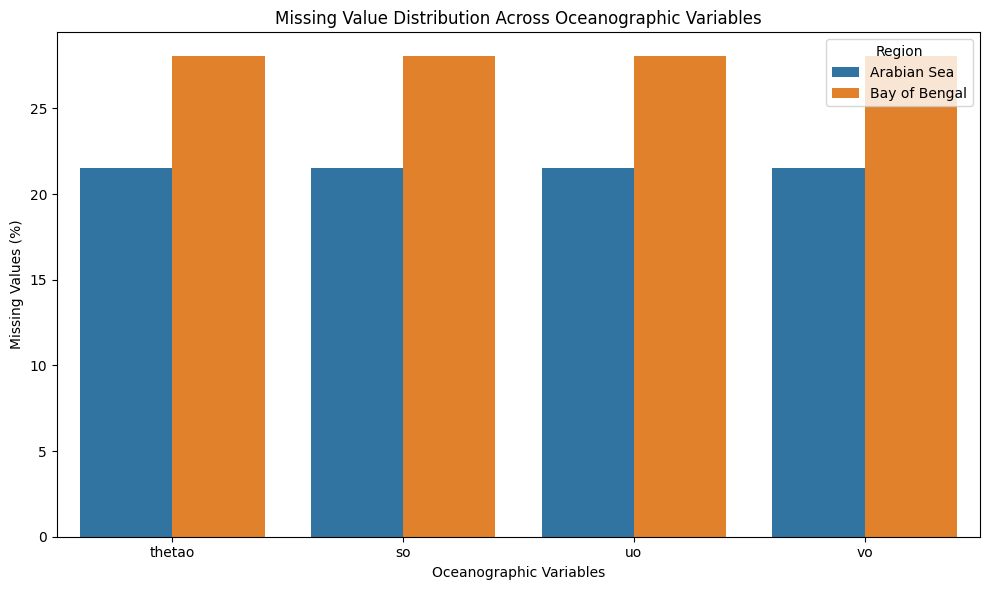

In [8]:
missing_comparison = pd.DataFrame({
    "Variable": ["thetao", "so", "uo", "vo"] * 2,
    "Missing Percentage": (
        arabian_missing["Missing (%)"].tolist()
        + bengal_missing["Missing (%)"].tolist()
    ),
    "Region": (
        ["Arabian Sea"] * 4
        + ["Bay of Bengal"] * 4
    )
})

plt.figure(figsize=(10, 6))

sns.barplot(
    data=missing_comparison,
    x="Variable",
    y="Missing Percentage",
    hue="Region"
)

plt.title("Missing Value Distribution Across Oceanographic Variables")
plt.ylabel("Missing Values (%)")
plt.xlabel("Oceanographic Variables")
plt.tight_layout()
plt.show()

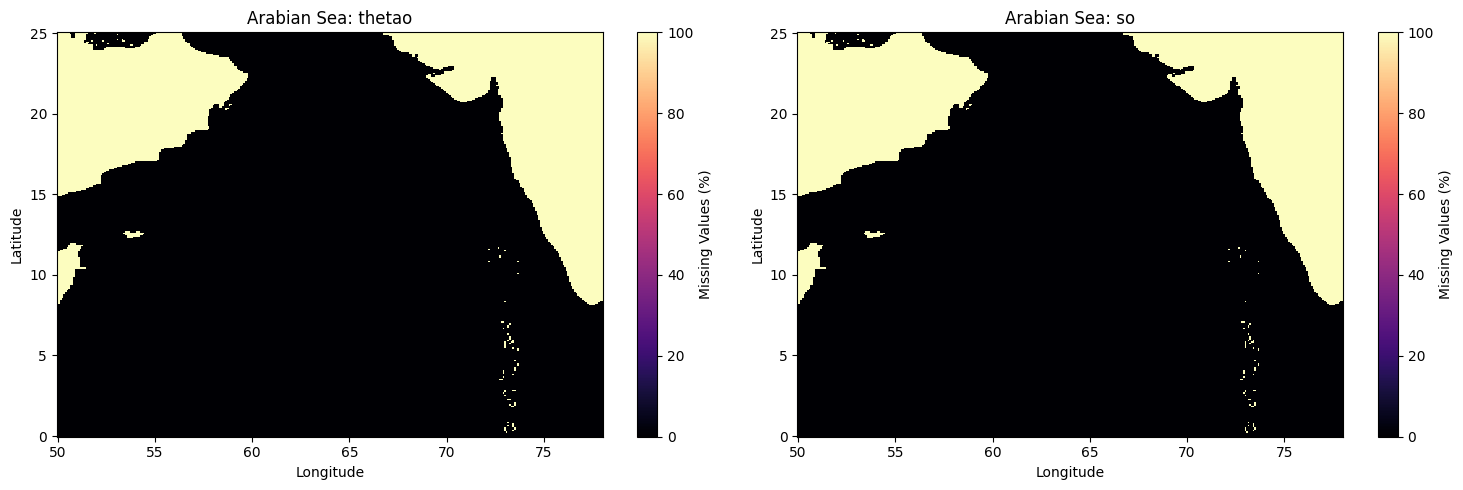

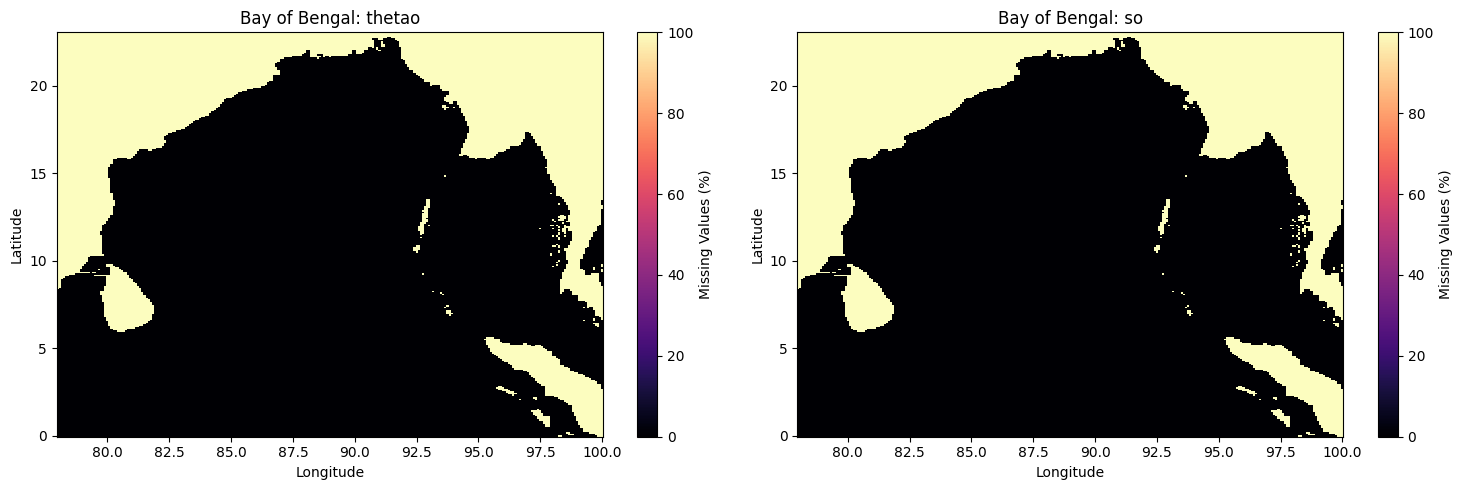

In [9]:
def plot_spatial_missing(ds, region):

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for ax, variable in zip(axes, ["thetao", "so"]):

        spatial_missing = (
            ds[variable]
            .isnull()
            .mean(dim=["time", "depth"])
            * 100
        )

        spatial_missing.plot(
            ax=ax,
            cmap="magma",
            cbar_kwargs={"label": "Missing Values (%)"}
        )

        ax.set_title(f"{region}: {variable}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    plt.tight_layout()
    plt.show()


plot_spatial_missing(arabian, "Arabian Sea")
plot_spatial_missing(bengal, "Bay of Bengal")

In [10]:
def spatial_missing_summary(ds, region):

    print(f"\n{'=' * 60}")
    print(f"SPATIAL MISSING SUMMARY: {region}")
    print('=' * 60)

    for variable in ds.data_vars:

        missing_pct = (
            ds[variable]
            .isnull()
            .mean(dim=["time", "depth"])
            .compute()
            * 100
        )

        total_cells = missing_pct.size
        complete = int((missing_pct == 0).sum().item())
        fully_missing = int((missing_pct == 100).sum().item())
        partial = int(
            ((missing_pct > 0) & (missing_pct < 100))
            .sum().item()
        )

        print(f"\nVariable: {variable}")
        print("Total grid cells:", total_cells)
        print("Complete cells:", complete)
        print("Fully missing cells:", fully_missing)
        print("Partially missing cells:", partial)


spatial_missing_summary(arabian, "ARABIAN SEA")
spatial_missing_summary(bengal, "BAY OF BENGAL")


SPATIAL MISSING SUMMARY: ARABIAN SEA

Variable: thetao
Total grid cells: 101437
Complete cells: 79618
Fully missing cells: 21819
Partially missing cells: 0

Variable: so
Total grid cells: 101437
Complete cells: 79618
Fully missing cells: 21819
Partially missing cells: 0

Variable: uo
Total grid cells: 101437
Complete cells: 79618
Fully missing cells: 21819
Partially missing cells: 0

Variable: vo
Total grid cells: 101437
Complete cells: 79618
Fully missing cells: 21819
Partially missing cells: 0

SPATIAL MISSING SUMMARY: BAY OF BENGAL

Variable: thetao
Total grid cells: 73405
Complete cells: 52827
Fully missing cells: 20578
Partially missing cells: 0

Variable: so
Total grid cells: 73405
Complete cells: 52827
Fully missing cells: 20578
Partially missing cells: 0

Variable: uo
Total grid cells: 73405
Complete cells: 52827
Fully missing cells: 20578
Partially missing cells: 0

Variable: vo
Total grid cells: 73405
Complete cells: 52827
Fully missing cells: 20578
Partially missing cells: 

In [11]:
def spatial_missing_table(ds, region):

    rows = []

    for variable in ds.data_vars:

        missing_pct = (
            ds[variable]
            .isnull()
            .mean(dim=["time", "depth"])
            .compute()
            * 100
        )

        rows.append({
            "Region": region,
            "Variable": variable,
            "Total Cells": missing_pct.size,
            "Complete": int((missing_pct == 0).sum()),
            "Fully Missing": int((missing_pct == 100).sum()),
            "Partial": int(
                ((missing_pct > 0) & (missing_pct < 100))
                .sum()
            )
        })

    return pd.DataFrame(rows)


spatial_results = pd.concat([
    spatial_missing_table(arabian, "Arabian Sea"),
    spatial_missing_table(bengal, "Bay of Bengal")
], ignore_index=True)

display(spatial_results)

,Region,Variable,Total Cells,Complete,Fully Missing,Partial
0,Arabian Sea,thetao,101437,79618,21819,0
1,Arabian Sea,so,101437,79618,21819,0
2,Arabian Sea,uo,101437,79618,21819,0
3,Arabian Sea,vo,101437,79618,21819,0
4,Bay of Bengal,thetao,73405,52827,20578,0
5,Bay of Bengal,so,73405,52827,20578,0
6,Bay of Bengal,uo,73405,52827,20578,0
7,Bay of Bengal,vo,73405,52827,20578,0


In [12]:
def monthly_validity(ds, region):

    results = []

    for variable in ds.data_vars:

        valid_percentage = (
            ds[variable]
            .notnull()
            .mean(dim=["depth", "latitude", "longitude"])
            .compute()
            * 100
        )

        df = valid_percentage.to_dataframe(
            name="Valid Percentage"
        ).reset_index()

        df["Region"] = region
        df["Variable"] = variable

        results.append(df)

    return pd.concat(results, ignore_index=True)


arabian_temporal = monthly_validity(arabian, "Arabian Sea")
bengal_temporal = monthly_validity(bengal, "Bay of Bengal")

temporal_data = pd.concat(
    [arabian_temporal, bengal_temporal],
    ignore_index=True
)

print(temporal_data.head())
print("\nTotal monthly observations:", len(temporal_data))

        time  Valid Percentage       Region Variable
0 2019-01-01         78.490097  Arabian Sea   thetao
1 2019-02-01         78.490097  Arabian Sea   thetao
2 2019-03-01         78.490097  Arabian Sea   thetao
3 2019-04-01         78.490097  Arabian Sea   thetao
4 2019-05-01         78.490097  Arabian Sea   thetao

Total monthly observations: 672


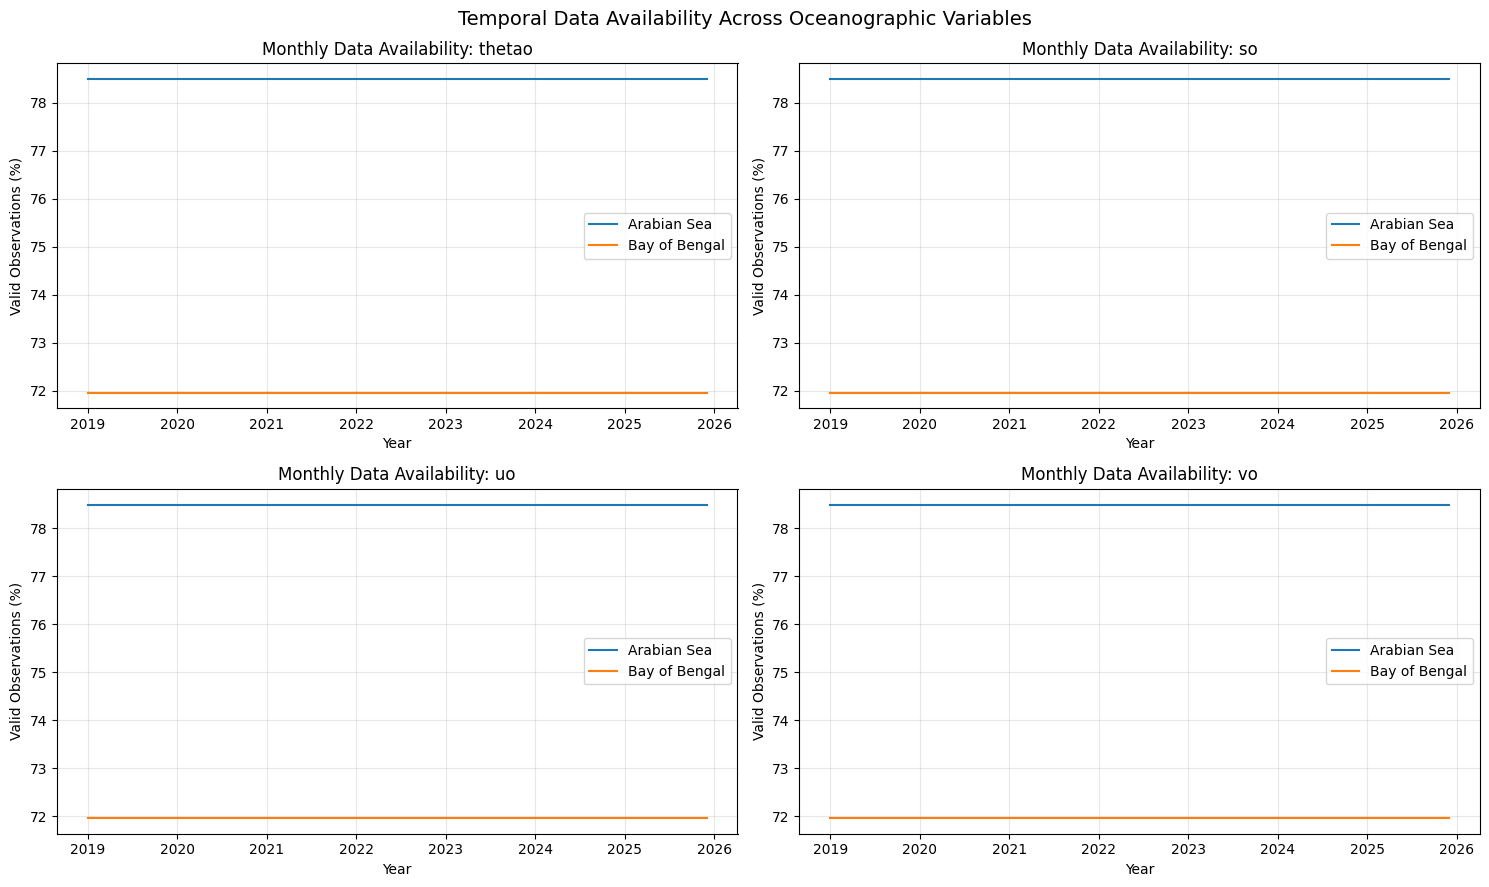

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

variables = ["thetao", "so", "uo", "vo"]

for ax, variable in zip(axes.flat, variables):

    subset = temporal_data[
        temporal_data["Variable"] == variable
    ]

    for region in ["Arabian Sea", "Bay of Bengal"]:

        region_data = subset[
            subset["Region"] == region
        ]

        ax.plot(
            region_data["time"],
            region_data["Valid Percentage"],
            label=region
        )

    ax.set_title(f"Monthly Data Availability: {variable}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Valid Observations (%)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Temporal Data Availability Across Oceanographic Variables",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [14]:
def monthly_variable_means(ds, region):

    results = []

    for variable in ds.data_vars:

        monthly_mean = (
            ds[variable]
            .mean(dim=["depth", "latitude", "longitude"], skipna=True)
            .compute()
        )

        df = monthly_mean.to_dataframe(
            name="Mean Value"
        ).reset_index()

        df["Region"] = region
        df["Variable"] = variable

        results.append(df)

    return pd.concat(results, ignore_index=True)


arabian_means = monthly_variable_means(
    arabian, "Arabian Sea"
)

bengal_means = monthly_variable_means(
    bengal, "Bay of Bengal"
)

monthly_means = pd.concat(
    [arabian_means, bengal_means],
    ignore_index=True
)

print(monthly_means.head(10))

        time  Mean Value       Region Variable
0 2019-01-01   27.033317  Arabian Sea   thetao
1 2019-02-01   27.032108  Arabian Sea   thetao
2 2019-03-01   27.823517  Arabian Sea   thetao
3 2019-04-01   29.396371  Arabian Sea   thetao
4 2019-05-01   30.196411  Arabian Sea   thetao
5 2019-06-01   29.766525  Arabian Sea   thetao
6 2019-07-01   28.517772  Arabian Sea   thetao
7 2019-08-01   27.914681  Arabian Sea   thetao
8 2019-09-01   28.215025  Arabian Sea   thetao
9 2019-10-01   28.936641  Arabian Sea   thetao


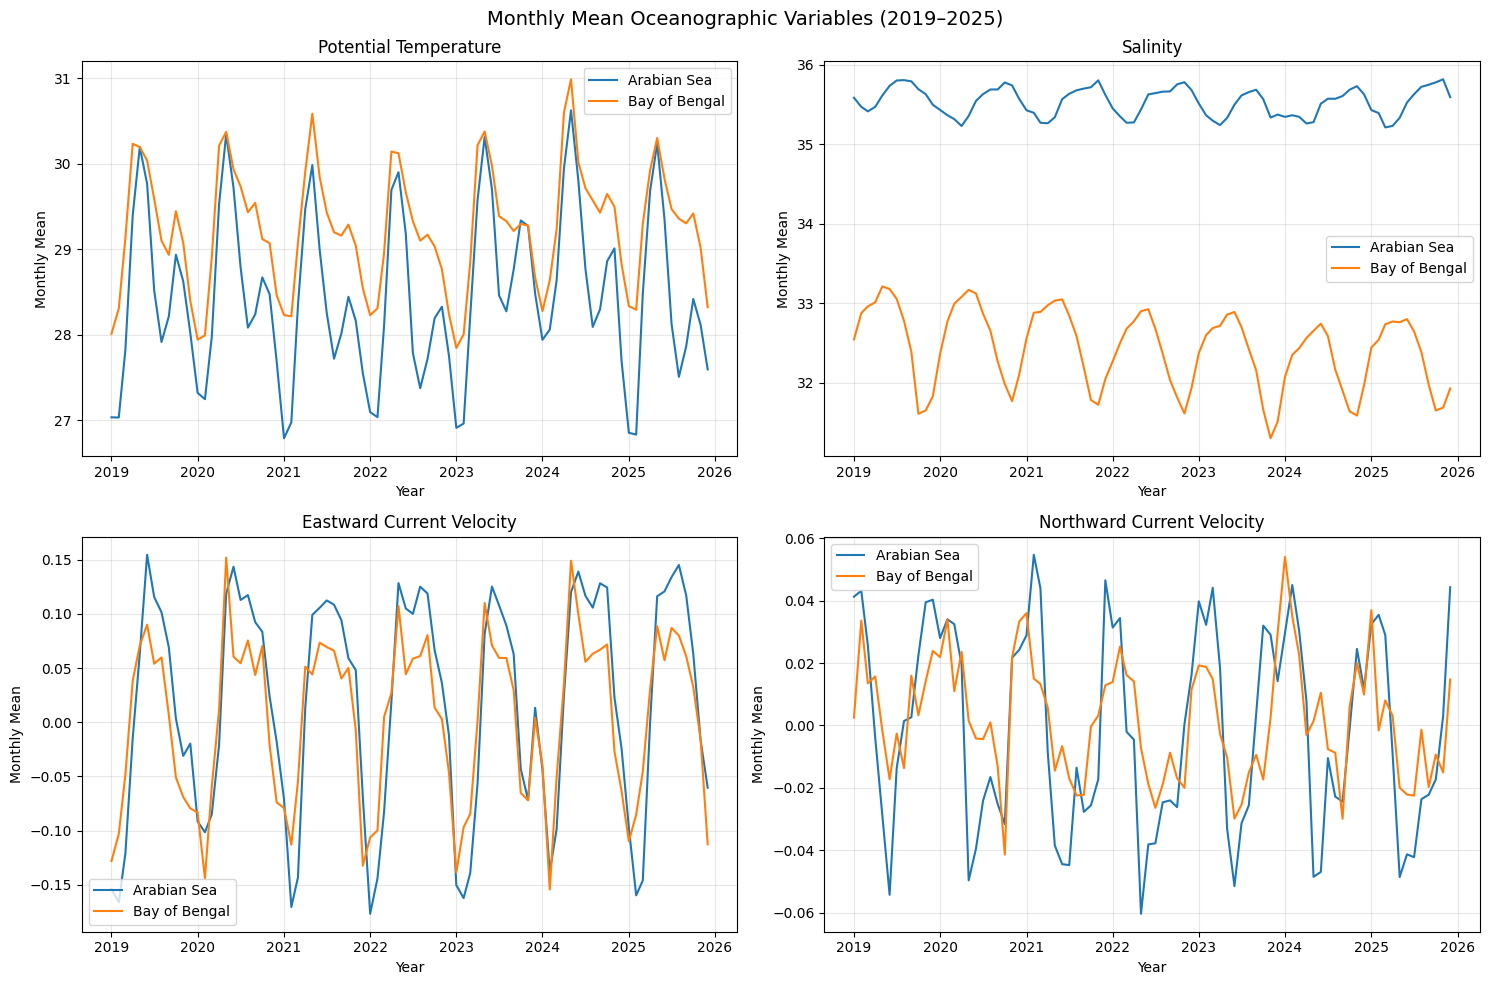

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

variables = ["thetao", "so", "uo", "vo"]

variable_names = {
    "thetao": "Potential Temperature",
    "so": "Salinity",
    "uo": "Eastward Current Velocity",
    "vo": "Northward Current Velocity"
}

for ax, variable in zip(axes.flat, variables):

    subset = monthly_means[
        monthly_means["Variable"] == variable
    ]

    for region in ["Arabian Sea", "Bay of Bengal"]:

        region_data = subset[
            subset["Region"] == region
        ]

        ax.plot(
            region_data["time"],
            region_data["Mean Value"],
            label=region
        )

    ax.set_title(variable_names[variable])
    ax.set_xlabel("Year")
    ax.set_ylabel("Monthly Mean")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Monthly Mean Oceanographic Variables (2019–2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [17]:
def descriptive_statistics(ds, region):

    rows = []

    for variable in ds.data_vars:

        values = ds[variable]

        # Convert DataArray to NumPy array
        stats = values.compute().values.flatten()

        # Remove missing values
        stats = stats[~pd.isna(stats)]

        rows.append({
            "Region": region,
            "Variable": variable,
            "Mean": stats.mean(),
            "Std": stats.std(),
            "Minimum": stats.min(),
            "25%": pd.Series(stats).quantile(0.25),
            "Median": pd.Series(stats).median(),
            "75%": pd.Series(stats).quantile(0.75),
            "Maximum": stats.max()
        })

    return pd.DataFrame(rows)


arabian_stats = descriptive_statistics(
    arabian, "Arabian Sea"
)

bengal_stats = descriptive_statistics(
    bengal, "Bay of Bengal"
)

copernicus_stats = pd.concat(
    [arabian_stats, bengal_stats],
    ignore_index=True
)

display(copernicus_stats.round(4))

,Region,Variable,Mean,Std,Minimum,25%,Median,75%,Maximum
0,Arabian Sea,thetao,28.4464,1.6137,16.3526,27.5092,28.7368,29.6040,36.2444
1,Arabian Sea,so,35.5322,0.9171,12.2623,35.0108,35.6105,36.1751,41.0611
2,Arabian Sea,uo,0.0166,0.2592,-1.7060,-0.0995,0.0146,0.1251,2.5935
3,Arabian Sea,vo,-0.0010,0.1783,-1.5784,-0.0873,-0.0092,0.0732,2.1747
4,Bay of Bengal,thetao,29.2444,1.0389,20.3745,28.8350,29.3316,29.8633,35.8137
5,Bay of Bengal,so,32.4312,2.7046,0.5982,31.9788,32.9981,33.7733,36.5291
6,Bay of Bengal,uo,0.0028,0.2088,-1.3367,-0.1056,-0.0024,0.0952,1.4924
7,Bay of Bengal,vo,0.0021,0.1495,-2.0856,-0.0696,-0.0018,0.0739,1.5461


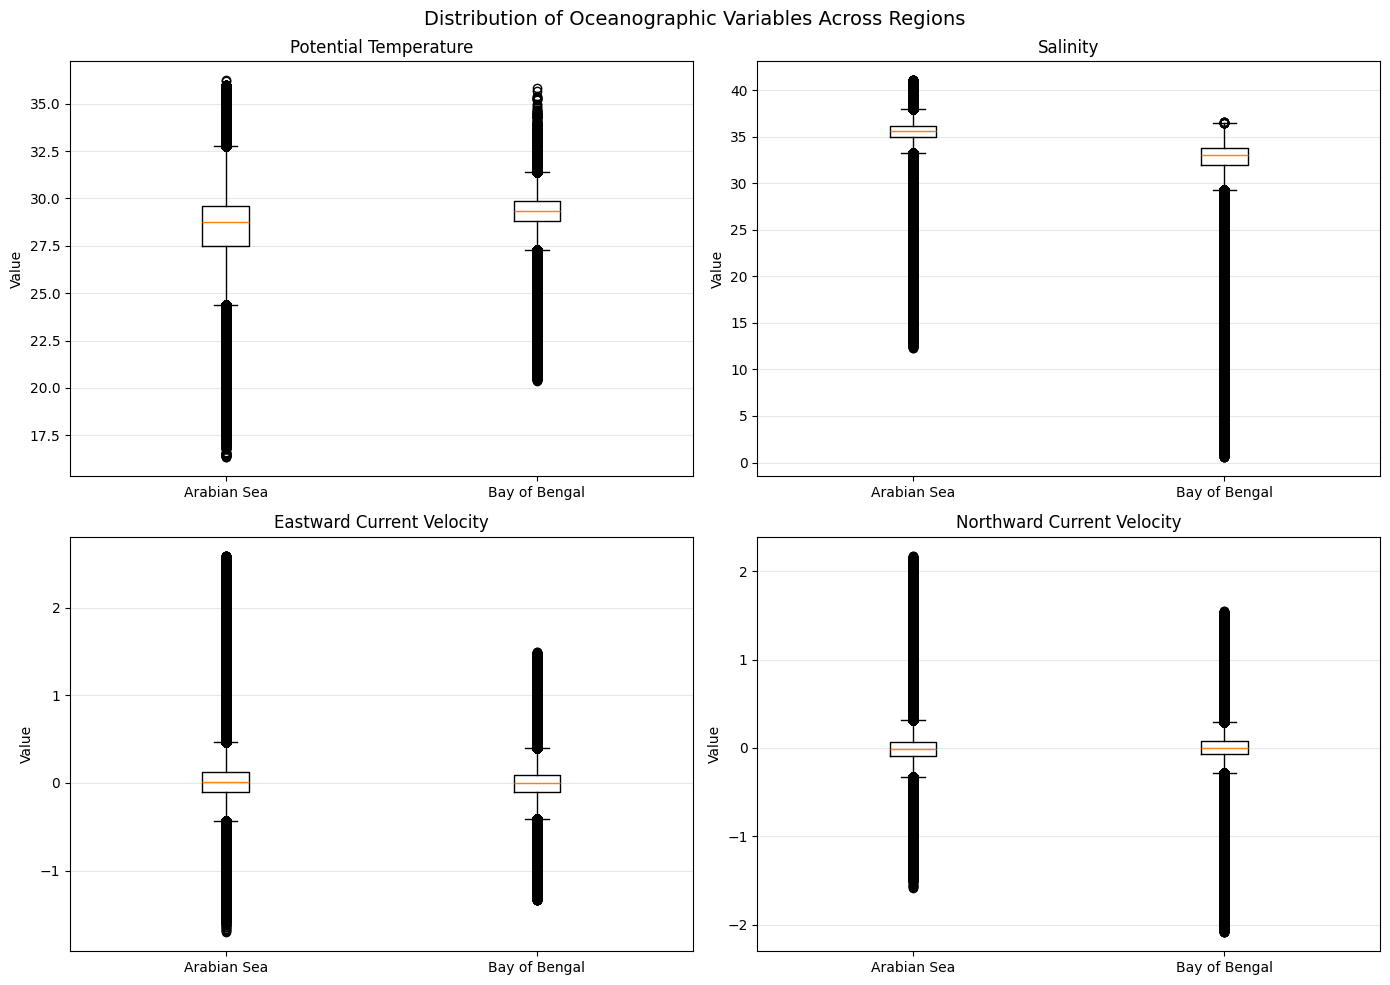

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

variables = ["thetao", "so", "uo", "vo"]

variable_names = {
    "thetao": "Potential Temperature",
    "so": "Salinity",
    "uo": "Eastward Current Velocity",
    "vo": "Northward Current Velocity"
}

for ax, variable in zip(axes.flat, variables):

    data = []

    for region, ds in [
        ("Arabian Sea", arabian),
        ("Bay of Bengal", bengal)
    ]:

        values = (
            ds[variable]
            .compute()
            .values
            .flatten()
        )

        values = values[~pd.isna(values)]

        data.append(values)

    ax.boxplot(
        data,
        tick_labels=["Arabian Sea", "Bay of Bengal"],
        showfliers=True
    )

    ax.set_title(variable_names[variable])
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distribution of Oceanographic Variables Across Regions",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [19]:
def inspect_salinity_extremes(ds, region):

    print(f"\n{'=' * 60}")
    print(f"SALINITY EXTREMES: {region}")
    print('=' * 60)

    salinity = ds["so"]

    minimum = salinity.min(
        dim=["time", "depth", "latitude", "longitude"]
    )

    maximum = salinity.max(
        dim=["time", "depth", "latitude", "longitude"]
    )

    print("Minimum salinity:", minimum.compute().item())
    print("Maximum salinity:", maximum.compute().item())

    # Find coordinates of extreme observations
    min_location = salinity.where(
        salinity == salinity.min(),
        drop=True
    )

    max_location = salinity.where(
        salinity == salinity.max(),
        drop=True
    )

    print("\nMinimum observation:")
    print(min_location.compute())

    print("\nMaximum observation:")
    print(max_location.compute())


inspect_salinity_extremes(arabian, "Arabian Sea")
inspect_salinity_extremes(bengal, "Bay of Bengal")


SALINITY EXTREMES: Arabian Sea
Minimum salinity: 12.26233709603548
Maximum salinity: 41.061128536239266

Minimum observation:
<xarray.DataArray 'so' (time: 1, depth: 1, latitude: 1, longitude: 1)> Size: 8B
array([[[[12.2623371]]]])
Coordinates:
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 4B 22.25
  * longitude  (longitude) float32 4B 72.5
  * time       (time) datetime64[ns] 8B 2021-10-01
Attributes:
    cell_methods:   area: mean
    long_name:      Salinity
    standard_name:  sea_water_salinity
    unit_long:      Practical Salinity Unit
    units:          1e-3
    valid_max:      31700
    valid_min:      1

Maximum observation:
<xarray.DataArray 'so' (time: 1, depth: 3, latitude: 1, longitude: 1)> Size: 24B
array([[[[41.06112854]],

        [[41.06112854]],

        [[41.06112854]]]])
Coordinates:
  * depth      (depth) float32 12B 0.494 1.541 2.646
  * latitude   (latitude) float32 4B 24.67
  * longitude  (longitude) float32 4B 54.67
  * time      

In [20]:

def inspect_extremes(ds, region, variable="so"):
    da = ds[variable]

    # Flatten the dataset dimensions into one index
    flat = da.stack(
        point=("time", "depth", "latitude", "longitude")
    )

    # Find minimum and maximum positions
    min_index = flat.argmin("point").compute().item()
    max_index = flat.argmax("point").compute().item()

    print(f"\n{'=' * 55}")
    print(f"{region} - {variable} EXTREME OBSERVATIONS")
    print("=" * 55)

    print("\nMINIMUM:")
    print(flat.isel(point=min_index).compute())

    print("\nMAXIMUM:")
    print(flat.isel(point=max_index).compute())


inspect_extremes(arabian, "Arabian Sea")
inspect_extremes(bengal, "Bay of Bengal")



Arabian Sea - so EXTREME OBSERVATIONS

MINIMUM:
<xarray.DataArray 'so' ()> Size: 8B
array(12.2623371)
Coordinates:
    point      object 8B (Timestamp('2021-10-01 00:00:00'), np.float32(0.4940...
    time       datetime64[ns] 8B 2021-10-01
    depth      float32 4B 0.494
    latitude   float32 4B 22.25
    longitude  float32 4B 72.5
Attributes:
    cell_methods:   area: mean
    long_name:      Salinity
    standard_name:  sea_water_salinity
    unit_long:      Practical Salinity Unit
    units:          1e-3
    valid_max:      31700
    valid_min:      1

MAXIMUM:
<xarray.DataArray 'so' ()> Size: 8B
array(41.06112854)
Coordinates:
    point      object 8B (Timestamp('2023-01-01 00:00:00'), np.float32(0.4940...
    time       datetime64[ns] 8B 2023-01-01
    depth      float32 4B 0.494
    latitude   float32 4B 24.67
    longitude  float32 4B 54.67
Attributes:
    cell_methods:   area: mean
    long_name:      Salinity
    standard_name:  sea_water_salinity
    unit_long:      Practi

In [21]:

def print_extremes(ds, region, variable="so"):
    da = ds[variable].compute()

    for label, operation in [
        ("MINIMUM", da.argmin),
        ("MAXIMUM", da.argmax)
    ]:
        index = operation(dim=list(da.dims))

        # Get coordinates at the extreme position
        positions = {
            dim: int(index[dim].item())
            for dim in da.dims
        }

        observation = da.isel(positions)

        print(f"\n{region} - {label}")
        print("Value:", round(float(observation.item()), 4))

        for coord in ["time", "depth", "latitude", "longitude"]:
            print(f"{coord}: {observation[coord].item()}")


print_extremes(arabian, "Arabian Sea")
print_extremes(bengal, "Bay of Bengal")



Arabian Sea - MINIMUM
Value: 12.2623
time: 1633046400000000000
depth: 0.49402499198913574
latitude: 22.25
longitude: 72.5

Arabian Sea - MAXIMUM
Value: 41.0611
time: 1672531200000000000
depth: 0.49402499198913574
latitude: 24.66666603088379
longitude: 54.66666793823242

Bay of Bengal - MINIMUM
Value: 0.5982
time: 1759276800000000000
depth: 0.49402499198913574
latitude: 22.16666603088379
longitude: 90.66666412353516

Bay of Bengal - MAXIMUM
Value: 36.5291
time: 1567296000000000000
depth: 2.6456689834594727
latitude: 9.416666984558105
longitude: 78.91666412353516


In [22]:

import numpy as np
import pandas as pd

extremes = [
    ("Arabian Sea", arabian, "2021-10-01", 22.25, 72.5),
    ("Arabian Sea", arabian, "2023-01-01", 24.6667, 54.6667),
    ("Bay of Bengal", bengal, "2025-10-01", 22.1667, 90.6667),
    ("Bay of Bengal", bengal, "2019-09-01", 9.4167, 78.9167)
]

for region, ds, date, lat, lon in extremes:
    da = ds["so"]

    time_index = int(
        np.argmin(
            np.abs(
                (da.time.values - np.datetime64(date))
                / np.timedelta64(1, "D")
            )
        )
    )

    lat_index = int(np.abs(da.latitude.values - lat).argmin())
    lon_index = int(np.abs(da.longitude.values - lon).argmin())

    neighborhood = da.isel(
        time=time_index,
        depth=0,
        latitude=slice(max(0, lat_index-1), lat_index+2),
        longitude=slice(max(0, lon_index-1), lon_index+2)
    ).compute()

    print("\n", "=" * 55)
    print(region, "|", date)
    print("Center:", lat, lon)
    print(neighborhood.to_pandas().round(3))



Arabian Sea | 2021-10-01
Center: 22.25 72.5
longitude  72.416664  72.500000  72.583336
latitude                                  
22.166666     12.983     12.545        NaN
22.250000     12.641     12.262        NaN
22.333334        NaN        NaN        NaN

Arabian Sea | 2023-01-01
Center: 24.6667 54.6667
longitude  54.583332  54.666668  54.750000
latitude                                  
24.583334     41.014        NaN        NaN
24.666666     41.038     41.061        NaN
24.750000     41.020     41.047        NaN

Bay of Bengal | 2025-10-01
Center: 22.1667 90.6667
longitude  90.583336  90.666664  90.750000
latitude                                  
22.083334      1.012      0.876      0.934
22.166666      0.676      0.598        NaN
22.250000        NaN        NaN        NaN

Bay of Bengal | 2019-09-01
Center: 9.4167 78.9167
longitude  78.833336  78.916664  79.000000
latitude                                  
9.333333         NaN        NaN        NaN
9.416667         NaN     36.